2. Distribution analysis
Menyelidiki distribusi schedule_variance_days, proporsi order terlambat, dan tingkat keparahan keterlambatan. Gunakan histogram dan box plot untuk melihat sebaran serta nilai ekstrem.


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [ ]:
data_path = Path("../../Data/Processed/dataco_cleaned.csv")

if not data_path.exists():
    raise FileNotFoundError(
        f"Processed dataset not found{data_path}\n"
    )

df = pd.read_csv(
    data_path,
    low_memory=False,
    parse_dates= [
        "order date (DateOrders)",
        "shipping date (DateOrders)"
    ],
)

print(f"loaded file: {data_path}")
print(f"rows:{len(df):,}")
print(f"columns: {df.shape[1]}")


loaded file: ../../Data/Processed/dataco_cleaned.csv
rows:180,519
columns: 64


,variance_days,item_count
0,-2,21666
1,-1,21700
2,0,33753
3,1,60647
4,2,28718
5,3,7052
6,4,6983


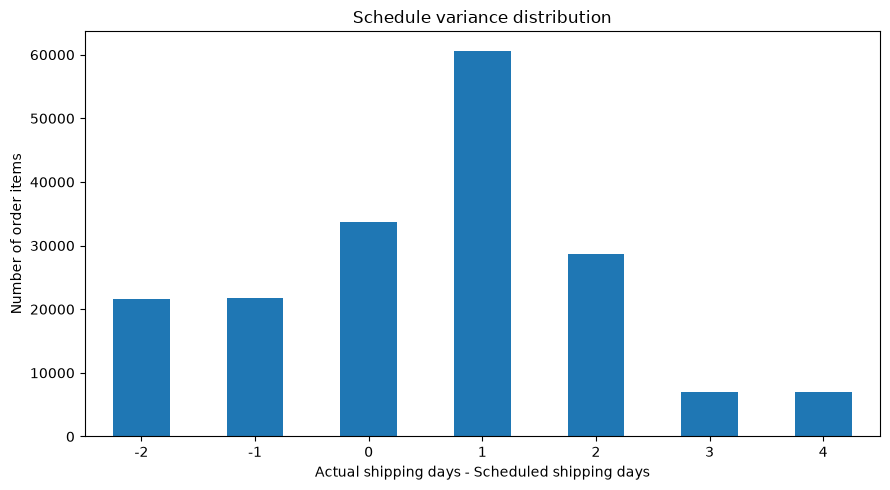

In [ ]:
# variance distribution

variance_counts = (
    df["schedule_variance_days"].value_counts().sort_index()
)
display(variance_counts.rename_axis("variance_days").reset_index(name="item_count"))

plt.figure(figsize=(9, 5))
variance_counts.plot(kind="bar")

plt.title("Schedule variance distribution")
plt.xlabel("Actual shipping days - Scheduled shipping days")
plt.ylabel("Number of order items")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Keterlambatan banyak terkonsentrasi pada selisih 1-2 hari dibanding 3-4 hari

In [ ]:
# delayed items

delayed_items = df.loc[df["delivery_timing"]=="Delayed"].copy()

delayed_summary = delayed_items["schedule_variance_days"].describe(percentiles=[0.25,0.50,0.75,0.90,0.95]).to_frame("delayed_variance_days")
display(delayed_summary)

,delayed_variance_days
count,"98,977.00"
mean,1.62
std,0.88
min,1.00
25%,1.00
50%,1.00
75%,2.00
90%,3.00
95%,4.00
max,4.00


Item yang terlambat rata-rata melebihi jadwal 1.62 hari , median 1 hari menunjukkan setidaknya separuh item terlambat memiliki variance paling tinggi 1 hari.

In [ ]:
#validate rule clasification

variance = df["schedule_variance_days"]
timing = df["delivery_timing"]

validation = pd.DataFrame({
    "check": [
        "delayed but variance <= 0",
        "not delayed but variance > 0",
        "canceled but variance is null",
        "unexpected delivery_timing"
    ],
    "count":[
        ((timing == "Delayed") & (variance <= 0)).sum(),
        ((timing == "Not delayed") & (variance > 0)).sum(),
        ((timing == "Canceled") & variance.isna()).sum(),
        (~timing.isin(["Delayed", "Not delayed", "Canceled"])).sum()
    ]
})

display(validation)


# kayak e gaperlu gasi?

,check,count
0,delayed but variance <= 0,0
1,not delayed but variance > 0,0
2,canceled but variance is null,0
3,unexpected delivery_timing,0
